<a href="https://colab.research.google.com/github/bayarerdenetest-ux/computer-vision/blob/main/notebooks/marmot_yolo26_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setup

pip install `ultralytics` and [dependencies](https://github.com/ultralytics/ultralytics/blob/main/pyproject.toml) and check software and hardware.

[![PyPI - Version](https://img.shields.io/pypi/v/ultralytics?logo=pypi&logoColor=white)](https://pypi.org/project/ultralytics/) [![Downloads](https://static.pepy.tech/badge/ultralytics)](https://clickpy.clickhouse.com/dashboard/ultralytics) [![PyPI - Python Version](https://img.shields.io/pypi/pyversions/ultralytics?logo=python&logoColor=gold)](https://pypi.org/project/ultralytics/)

In [ ]:
!uv pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!unzip -q "/content/drive/MyDrive/merged_marmot.zip" -d /content/imgs

import xml.etree.ElementTree as ET, pathlib, random, shutil
XML = "/content/drive/MyDrive/merged_fixed.xml"
SRC = pathlib.Path("/content/imgs")
OUT = pathlib.Path("/content/dataset")
root = ET.parse(XML).getroot()
ims = root.findall("image")
random.seed(0); random.shuffle(ims)
n_val = int(len(ims) * 0.2)
for i, im in enumerate(ims):
    s = "val" if i < n_val else "train"
    (OUT/"images"/s).mkdir(parents=True, exist_ok=True)
    (OUT/"labels"/s).mkdir(parents=True, exist_ok=True)
    name = im.get("name")
    W, H = float(im.get("width")), float(im.get("height"))
    shutil.copy(SRC/name, OUT/"images"/s/name)
    lines = []
    for b in im.findall("box"):
        x1, y1, x2, y2 = (float(b.get(k)) for k in ("xtl", "ytl", "xbr", "ybr"))
        lines.append(f"0 {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
    (OUT/"labels"/s/(pathlib.Path(name).stem + ".txt")).write_text("\n".join(lines))
(OUT/"data.yaml").write_text("path: /content/dataset\ntrain: images/train\nval: images/val\nnames:\n  0: dosh\n")
print(len(ims), "images, val:", n_val)

In [ ]:
!yolo train model=yolo26n.pt data=/content/dataset/data.yaml epochs=100 imgsz=1280 batch=8

In [ ]:
!cp /content/runs/detect/train/weights/best.pt /content/drive/MyDrive/marmot_best.pt

In [ ]:
!yolo predict model=/content/runs/detect/train/weights/best.pt source=/content/dataset/images/val imgsz=1280 save=True

In [ ]:
!yolo predict model=/content/runs/detect/train/weights/best.pt source=/content/dataset/images/val/DJI_0403.JPG imgsz=1280 conf=0.5 save=True name=check

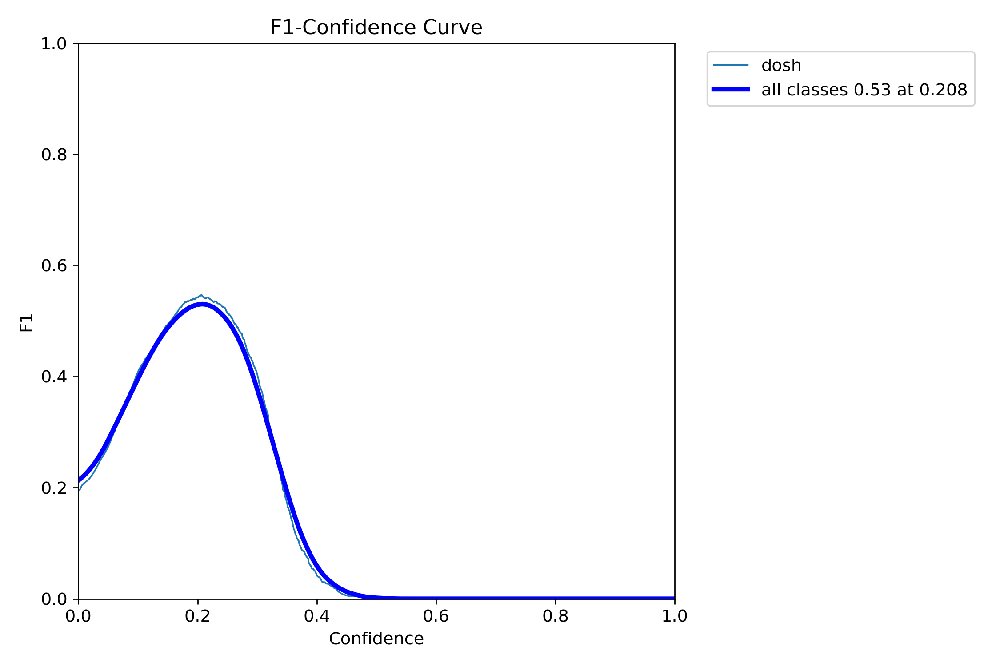

In [ ]:
from IPython.display import Image, display
display(Image("/content/runs/detect/train/BoxF1_curve.png", width=800))


In [ ]:
!yolo predict model=/content/runs/detect/train/weights/best.pt source=/content/dataset/images/val imgsz=1280 conf=0.2 save=True name=final

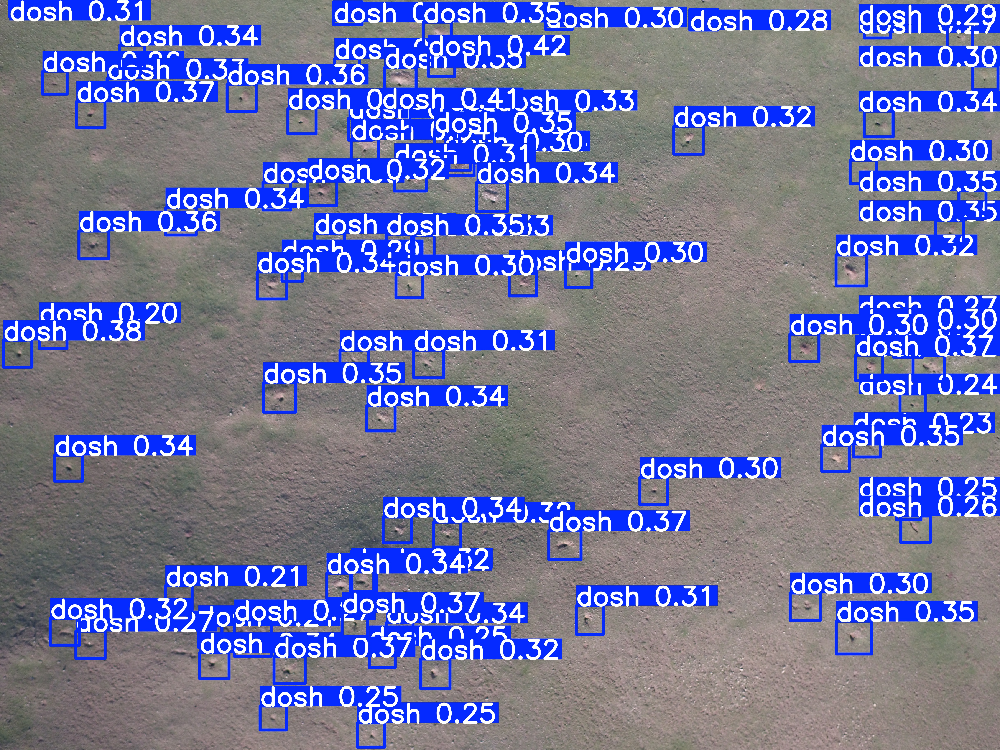

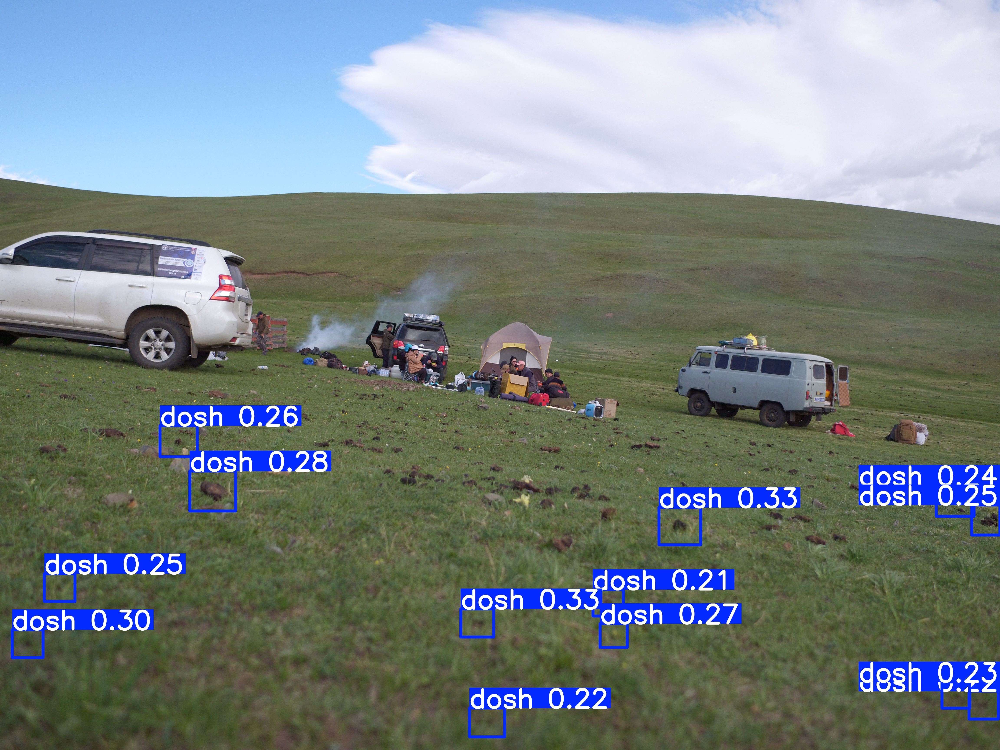

In [ ]:
from IPython.display import Image, display
for n in ["DJI_0405", "DJI_0403"]:
    display(Image(f"/content/runs/detect/final/{n}.JPG", width=900))

In [ ]:
!ls /content/dataset/images/train | wc -l
!nvidia-smi | head -n 12

ls: cannot access '/content/dataset/images/train': No such file or directory
0
Wed Oct  7 15:27:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                  

In [ ]:
!uv pip install ultralytics


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!unzip -q "/content/drive/MyDrive/merged_marmot.zip" -d /content/imgs

import xml.etree.ElementTree as ET, pathlib, random, shutil
XML = "/content/drive/MyDrive/merged_fixed.xml"
SRC = pathlib.Path("/content/imgs")
OUT = pathlib.Path("/content/dataset")
root = ET.parse(XML).getroot()
ims = root.findall("image")
random.seed(0); random.shuffle(ims)
n_val = int(len(ims) * 0.2)
for i, im in enumerate(ims):
    s = "val" if i < n_val else "train"
    (OUT/"images"/s).mkdir(parents=True, exist_ok=True)
    (OUT/"labels"/s).mkdir(parents=True, exist_ok=True)
    name = im.get("name")
    W, H = float(im.get("width")), float(im.get("height"))
    shutil.copy(SRC/name, OUT/"images"/s/name)
    lines = []
    for b in im.findall("box"):
        x1, y1, x2, y2 = (float(b.get(k)) for k in ("xtl", "ytl", "xbr", "ybr"))
        lines.append(f"0 {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
    (OUT/"labels"/s/(pathlib.Path(name).stem + ".txt")).write_text("\n".join(lines))
(OUT/"data.yaml").write_text("path: /content/dataset\ntrain: images/train\nval: images/val\nnames:\n  0: dosh\n")
print(len(ims), "images, val:", n_val)

In [ ]:
import ultralytics, pathlib
p = pathlib.Path(ultralytics.__file__).parent / "cfg/models/26/yolo26-p2.yaml"
print(p.read_text())

In [ ]:
import ultralytics, pathlib
src = pathlib.Path(ultralytics.__file__).parent / "cfg/models/26/yolo26-p2.yaml"
t = src.read_text()
cut = """  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]] # cat head P5
  - [-1, 1, C3k2, [1024, True, 0.5, True]] # 28 (P5/32-large)

"""
assert cut in t, "P5 block not found"
t = t.replace(cut, "")
old = "  - [[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)"
assert old in t, "Detect line not found"
t = t.replace(old, "  - [[19, 22, 25], 1, Detect, [nc]] # Detect(P2, P3, P4)")
pathlib.Path("/content/yolo26n-p234.yaml").write_text(t)
print("ok")

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/yolo26n-p234.yaml").load("yolo26n.pt")
model.train(data="/content/dataset/data.yaml", epochs=100, imgsz=1280, batch=8,
            project="/content/drive/MyDrive/runs", name="p234")